# Student Performance Analysis Using Python

## Project Overview
This project analyzes student performance data to explore academic results and examine factors related to students' achievement.

## Project Objectives
- Analyze students' final grades in Mathematics and Portuguese.
- Explore the relationship between study time and academic performance.
- Examine the relationship between student absences and final grades.
- Compare academic performance across different subjects.
- Apply data cleaning, transformation, aggregation, and visualization using Python.

## Dataset Source
UCI Machine Learning Repository – Student Performance Dataset.

https://archive.ics.uci.edu/dataset/320/student+performance

In [28]:
import urllib.request
import zipfile
import os

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

urllib.request.urlretrieve(url, "student_performance.zip")

# Extract the downloaded files
with zipfile.ZipFile("student_performance.zip", "r") as zip_ref:
    zip_ref.extractall("student_data")

# Display extracted files
print("Dataset downloaded and extracted successfully!")
print(os.listdir("student_data"))

Dataset downloaded and extracted successfully!
['.student.zip_old', 'student.zip', 'files']


In [29]:
import zipfile
import os

# Extract the inner ZIP file
with zipfile.ZipFile("student_data/student.zip", "r") as zip_ref:
    zip_ref.extractall("student_data/files")

# Display the extracted files
print("Files extracted successfully!")
print(os.listdir("student_data/files"))

Files extracted successfully!
['student-mat.csv', 'student-merge.R', 'student-por.csv', 'student.txt']


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
math_df = pd.read_csv("student_data/files/student-mat.csv", sep=";")
port_df = pd.read_csv("student_data/files/student-por.csv", sep=";")

print("Libraries imported successfully!")
print("Math dataset shape:", math_df.shape)
print("Portuguese dataset shape:", port_df.shape)

Libraries imported successfully!
Math dataset shape: (395, 33)
Portuguese dataset shape: (649, 33)


In [31]:
# Display the first 5 rows
print("Mathematics Dataset:")
display(math_df.head())

print("Portuguese Dataset:")
display(port_df.head())

# Display column names
print("Column Names:")
print(math_df.columns.tolist())

Mathematics Dataset:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Portuguese Dataset:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [32]:
# Check data types
print("Mathematics Dataset Information:")
math_df.info()

print("\nPortuguese Dataset Information:")
port_df.info()

# Check missing values
print("\nMissing Values in Mathematics:")
print(math_df.isnull().sum().sum())

print("\nMissing Values in Portuguese:")
print(port_df.isnull().sum().sum())

Mathematics Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 n

In [33]:
# Check duplicate records
print("Duplicate rows in Mathematics:", math_df.duplicated().sum())

print("Duplicate rows in Portuguese:", port_df.duplicated().sum())

Duplicate rows in Mathematics: 0
Duplicate rows in Portuguese: 0


In [34]:
# Check final grade ranges
print("Mathematics G3 range:")
print(math_df["G3"].min(), "to", math_df["G3"].max())

print("\nPortuguese G3 range:")
print(port_df["G3"].min(), "to", port_df["G3"].max())

# Check negative absences
print("\nNegative absences in Mathematics:",
      (math_df["absences"] < 0).sum())

print("Negative absences in Portuguese:",
      (port_df["absences"] < 0).sum())

Mathematics G3 range:
0 to 20

Portuguese G3 range:
0 to 19

Negative absences in Mathematics: 0
Negative absences in Portuguese: 0


In [35]:
# Add subject labels
math_df["Subject"] = "Mathematics"
port_df["Subject"] = "Portuguese"

# Combine both datasets
students_df = pd.concat(
    [math_df, port_df],
    ignore_index=True
)

# Display the combined dataset information
print("Combined Dataset Shape:", students_df.shape)

print("\nSubject Distribution:")
print(students_df["Subject"].value_counts())

display(students_df.head())

Combined Dataset Shape: (1044, 34)

Subject Distribution:
Subject
Portuguese     649
Mathematics    395
Name: count, dtype: int64


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,Mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,Mathematics


In [36]:
# Display descriptive statistics for numerical columns
print("Descriptive Statistics:")
display(students_df.describe())

# Display descriptive statistics for categorical columns
print("Categorical Data Summary:")
display(students_df.describe(include="object"))

Descriptive Statistics:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,16.726054,2.603448,2.387931,1.522989,1.970307,0.264368,3.935824,3.201149,3.156130,1.494253,2.284483,3.543103,4.434866,11.213602,11.246169,11.341954
std,1.239975,1.124907,1.099938,0.731727,0.834353,0.656142,0.933401,1.031507,1.152575,0.911714,1.285105,1.424703,6.210017,2.983394,3.285071,3.864796
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,9.000000,9.000000,10.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Categorical Data Summary:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,Subject
count,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044,1044
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,no,yes,yes,yes,no,Portuguese
freq,772,591,759,738,923,399,584,430,728,925,640,824,528,835,955,827,673,649


In [37]:
# Calculate the average grade
students_df["Average_Grade"] = students_df[
    ["G1", "G2", "G3"]
].mean(axis=1)

# Display selected columns
display(
    students_df[
        ["Subject", "G1", "G2", "G3", "Average_Grade"]
    ].head()
)

print("\nUpdated Dataset Shape:", students_df.shape)

,Subject,G1,G2,G3,Average_Grade
0,Mathematics,5,6,6,5.666667
1,Mathematics,5,5,6,5.333333
2,Mathematics,7,8,10,8.333333
3,Mathematics,15,14,15,14.666667
4,Mathematics,6,10,10,8.666667



Updated Dataset Shape: (1044, 35)


In [38]:
# Group data by subject and calculate performance statistics
subject_analysis = students_df.groupby("Subject")["G3"].agg(
    ["mean", "max", "min", "count"]
).reset_index()

# Rename columns for clarity
subject_analysis.columns = [
    "Subject",
    "Average_Final_Grade",
    "Highest_Grade",
    "Lowest_Grade",
    "Number_of_Records"
]

display(subject_analysis)

,Subject,Average_Final_Grade,Highest_Grade,Lowest_Grade,Number_of_Records
0,Mathematics,10.415190,20,0,395
1,Portuguese,11.906009,19,0,649


In [39]:
# Analyze average final grades by study time and subject
study_analysis = students_df.groupby(
    ["Subject", "studytime"]
)["G3"].mean().reset_index()

# Rename columns
study_analysis.columns = [
    "Subject",
    "Study_Time",
    "Average_Final_Grade"
]

display(study_analysis)

,Subject,Study_Time,Average_Final_Grade
0,Mathematics,1,10.047619
1,Mathematics,2,10.171717
2,Mathematics,3,11.400000
3,Mathematics,4,11.259259
4,Portuguese,1,10.844340
5,Portuguese,2,12.091803
6,Portuguese,3,13.226804
7,Portuguese,4,13.057143


In [40]:
# Analyze average final grades by number of absences
absence_analysis = students_df.groupby(
    ["Subject", "absences"]
)["G3"].mean().reset_index()

# Rename columns
absence_analysis.columns = [
    "Subject",
    "Absences",
    "Average_Final_Grade"
]

# Display the first 15 rows
display(absence_analysis.head(15))

,Subject,Absences,Average_Final_Grade
0,Mathematics,0,8.443478
1,Mathematics,1,13.000000
2,Mathematics,2,11.907692
3,Mathematics,3,11.500000
4,Mathematics,4,11.283019
5,Mathematics,5,11.600000
6,Mathematics,6,11.774194
7,Mathematics,7,11.857143
8,Mathematics,8,10.590909
9,Mathematics,9,13.333333


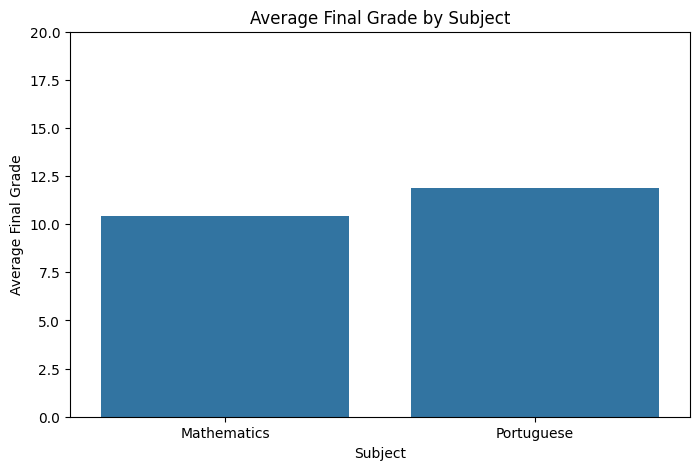

In [41]:
# Plot average final grades by subject
plt.figure(figsize=(8, 5))

sns.barplot(
    data=subject_analysis,
    x="Subject",
    y="Average_Final_Grade"
)

plt.title("Average Final Grade by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Final Grade")
plt.ylim(0, 20)

plt.show()

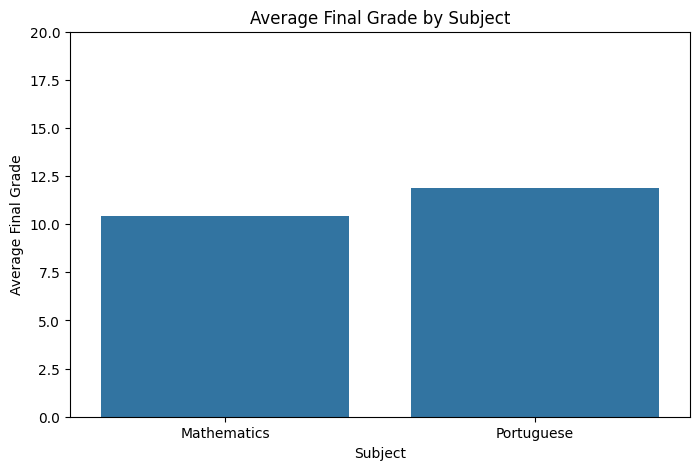

In [42]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create output folder
os.makedirs("outputs/figures", exist_ok=True)

# Create the chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=subject_analysis,
    x="Subject",
    y="Average_Final_Grade"
)

plt.title("Average Final Grade by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Final Grade")
plt.ylim(0, 20)

# Save the chart
plt.savefig(
    "outputs/figures/average_grade_by_subject.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

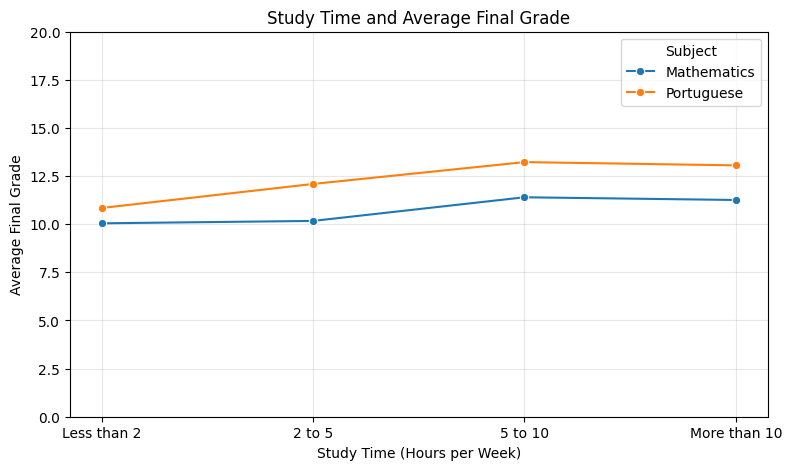

In [43]:
# Create output folder if it does not exist
os.makedirs("outputs/figures", exist_ok=True)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=study_analysis,
    x="Study_Time",
    y="Average_Final_Grade",
    hue="Subject",
    marker="o"
)

plt.title("Study Time and Average Final Grade")
plt.xlabel("Study Time (Hours per Week)")
plt.ylabel("Average Final Grade")
plt.xticks([1, 2, 3, 4], [
    "Less than 2",
    "2 to 5",
    "5 to 10",
    "More than 10"
])
plt.ylim(0, 20)
plt.legend(title="Subject")
plt.grid(alpha=0.3)

plt.savefig(
    "outputs/figures/study_time_vs_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

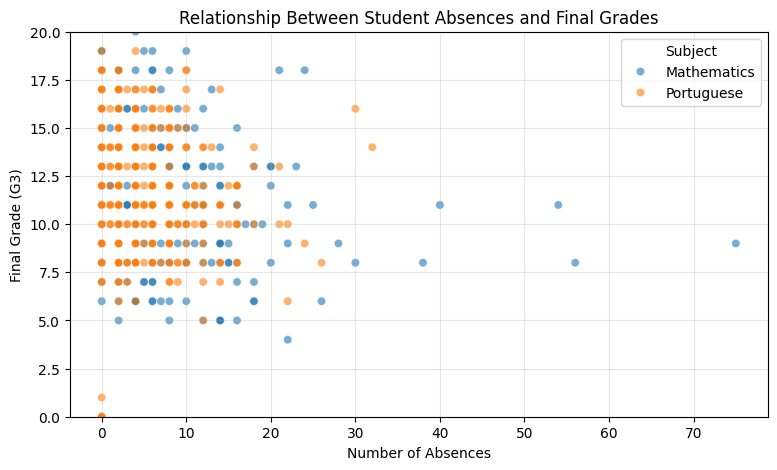

In [44]:
# Create the scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=students_df,
    x="absences",
    y="G3",
    hue="Subject",
    alpha=0.6
)

plt.title("Relationship Between Student Absences and Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.ylim(0, 20)
plt.legend(title="Subject")
plt.grid(alpha=0.3)

# Save the chart
plt.savefig(
    "outputs/figures/absences_vs_final_grade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Visualization Results and Interpretation

### 1. Average Final Grade by Subject
The analysis shows that Portuguese students achieved a higher average final grade (11.91) compared to Mathematics students (10.42). This indicates a difference in average academic performance between the two subject datasets.

### 2. Study Time and Academic Performance
The results show a general increase in average final grades as weekly study time increases up to the 5–10 hours category in both subjects. However, students studying more than 10 hours did not achieve the highest average grades. This suggests that study time is associated with academic performance, but it may not be the only influencing factor.

### 3. Relationship Between Absences and Final Grades
The scatter plot illustrates the distribution of final grades across different absence levels. The points show variation in student performance, and no definite causal relationship can be established from this visualization alone. Further statistical analysis would be needed to measure the strength of the relationship.

In [45]:
# Save the final cleaned dataset
students_df.to_csv(
    "student_performance_cleaned.csv",
    index=False
)

print("Final dataset saved successfully!")
print("Final dataset shape:", students_df.shape)

Final dataset saved successfully!
Final dataset shape: (1044, 35)


In [46]:
import os

print("Project Files:")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".config", "__pycache__"]]

    for file in files:
        if not file.startswith("."):
            print(os.path.join(root, file))

Project Files:
./student_performance.zip
./student_performance_cleaned.csv
./Student-Performance-Analysis/data/student_performance_cleaned.csv
./Student-Performance-Analysis/data/README.md
./Student-Performance-Analysis/outputs/figures/absences_vs_final_grade.png
./Student-Performance-Analysis/outputs/figures/average_grade_by_subject.png
./Student-Performance-Analysis/outputs/figures/study_time_vs_performance.png
./outputs/figures/absences_vs_final_grade.png
./outputs/figures/average_grade_by_subject.png
./outputs/figures/study_time_vs_performance.png
./student_data/student.zip
./student_data/files/student-mat.csv
./student_data/files/student-merge.R
./student_data/files/student-por.csv
./student_data/files/student.txt
./sample_data/anscombe.json
./sample_data/README.md
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/california_housing_test.csv


In [47]:
import os
import shutil

# Create project folders
os.makedirs("Student-Performance-Analysis/data", exist_ok=True)
os.makedirs("Student-Performance-Analysis/notebooks", exist_ok=True)
os.makedirs("Student-Performance-Analysis/outputs/figures", exist_ok=True)

# Copy the cleaned dataset
shutil.copy(
    "student_performance_cleaned.csv",
    "Student-Performance-Analysis/data/student_performance_cleaned.csv"
)

# Copy the visualization files
for file in os.listdir("outputs/figures"):
    shutil.copy(
        os.path.join("outputs/figures", file),
        os.path.join("Student-Performance-Analysis/outputs/figures", file)
    )

print("Project folders and files organized successfully!")

Project folders and files organized successfully!


## Descriptive Statistics and Data Understanding

The descriptive statistics provide an overview of the combined student performance dataset, which contains 1,044 records and 35 columns.

The average student age is approximately 16.73 years, while the average final grade (G3) is 11.34 out of 20. The average number of absences is approximately 4.43.

The study time variable has an average value of 1.97. However, this variable represents categories of weekly study time rather than exact hours.

The categorical summary shows that the dataset includes two subjects: Mathematics and Portuguese, with 395 and 649 records respectively.

The data quality checks found no missing values or duplicate records in either original dataset. These results indicate that the datasets are complete in terms of missing-value checks and do not contain exact duplicate rows.

In [48]:
data_readme = """
# Data Documentation

## Dataset Name
Student Performance Dataset

## Data Source
UCI Machine Learning Repository:
https://archive.ics.uci.edu/dataset/320/student+performance

## Original Data Files
The original dataset contains two CSV files:

- student-mat.csv: Mathematics student records (395 rows).
- student-por.csv: Portuguese student records (649 rows).

Both files contain 33 columns describing student characteristics,
study habits, absences, and academic grades.

## Data Format
The original CSV files use a semicolon (;) as a separator.

## Data Preparation
The two datasets were loaded separately using Pandas.
A Subject column was added to identify each subject.
The datasets were then concatenated into one combined dataset.

An additional column, Average_Grade, was calculated
as the mean of G1, G2, and G3.

## Final Dataset
File: student_performance_cleaned.csv

Shape: 1044 rows and 35 columns.

The final dataset is stored in this folder.

## Data Quality
- No missing values were found.
- No duplicate rows were found.
- No negative absence values were found.

## Important Note
The two subject datasets were concatenated, not merged using
individual student identifiers. Therefore, the combined records
should not be interpreted as matched individual students.
"""

with open(
    "Student-Performance-Analysis/data/README.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(data_readme)

print("Data README created successfully!")

Data README created successfully!


In [50]:
readme_content = """
# Student Performance Analysis Using Python

## 1. Project Overview

This project analyzes student performance data in Mathematics and Portuguese.
It explores academic results and examines factors related to students' achievement.

## 2. Project Objectives

- Analyze students' final grades in Mathematics and Portuguese.
- Compare academic performance across different subjects.
- Explore the relationship between study time and final grades.
- Examine the relationship between student absences and final grades.
- Apply data cleaning, transformation, aggregation, and visualization techniques.

## 3. Dataset Source

UCI Machine Learning Repository – Student Performance Dataset.

https://archive.ics.uci.edu/dataset/320/student+performance

The dataset includes two original files:
- Mathematics: 395 records.
- Portuguese: 649 records.

## 4. Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## 5. Data Preparation

The following steps were performed:

- Loaded both subject datasets.
- Inspected dataset dimensions, columns, and data types.
- Checked missing values and duplicate records.
- Checked grade ranges and negative absence values.
- Added a Subject column.
- Combined the datasets using concatenation.
- Created an Average_Grade column.
- Aggregated final grades by subject and study time.

## 6. Data Analysis and Main Findings

- Mathematics average final grade: 10.42.
- Portuguese average final grade: 11.91.
- Average final grade generally increased with study time up to the 5–10 hours category.
- The scatter plot shows variation in final grades across different absence levels.

## 7. Visualizations

Three visualizations were created:

1. Average Final Grade by Subject.
2. Study Time and Average Final Grade.
3. Relationship Between Student Absences and Final Grades.

The figures are available in the outputs/figures folder.

## 8. Data Quality

- No missing values were found.
- No duplicate rows were found.
- No negative absence values were found.

## 9. Limitations

- The two subject datasets have different numbers of records.
- The datasets were concatenated, not matched using individual student identifiers.
- The analysis describes associations and does not establish causation.
- Other factors may influence academic performance.

## 10. Reproducibility

The analysis was developed in Google Colab.

To reproduce the analysis:
1. Open the notebook in Google Colab.
2. Run all cells from top to bottom.
3. The notebook downloads and extracts the original dataset.
4. The notebook performs data preparation, analysis, and visualization.

Required libraries: pandas, numpy, matplotlib, and seaborn.

## 11. Team Contributions

Team member names and individual contributions should be added here.

## 12. Project Structure

- data/: Cleaned dataset and data documentation.
- notebooks/: Project analysis notebook.
- outputs/figures/: Generated visualizations.
- README.md: Project documentation.
"""

with open(
    "Student-Performance-Analysis/README.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(readme_content)

print("Main README created successfully!")

Main README created successfully!


In [51]:
import os

project_folder = "Student-Performance-Analysis"

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Student-Performance-Analysis/
    README.md
    data/
        student_performance_cleaned.csv
        README.md
    notebooks/
    outputs/
        figures/
            absences_vs_final_grade.png
            average_grade_by_subject.png
            study_time_vs_performance.png
